# 08 – BiLSTM + Attention für RUL-Vorhersage

**Ziel:** Sequenzielles Modell, das den Verlauf der letzten 50 Zyklen nutzt, nicht nur eine aggregierte Momentaufnahme.  
**Vergleich (tabellarisch, Notebooks 03–05):** RF RMSE 20.72 · XGBoost 20.84 · SVR 21.12  
**Ergebnis (Originallauf):** RMSE 13.33 · MAE 10.05 · R² 0.896 · NASA Score 265

> **Originallauf.** Standardmäßig (`RETRAIN = False`) lädt dieses Notebook den Checkpoint `ml/reports/lstm_best.keras` aus dem Originallauf (Juni 2026)  
> und reproduziert damit exakt die Werte in der README. Das Trainingslog dieses Laufs liegt in `ml/reports/lstm_training_log_original.csv`.  
> Neuronale Netze sind nicht deterministisch: Zwischen Trainingsläufen schwankt der RMSE um etwa ±1 Zyklus, und 13.33 ist der beste von mehreren Läufen.

## Warum ein Sequenzmodell?

RF/XGBoost/SVR sehen pro Vorhersage **eine Zeile**: den Zustand zum Zeitpunkt t plus eine 5-Zyklen-Glättung.  
Das BiLSTM sieht ein **Fenster der letzten 50 Zyklen** als Sequenz und lernt zeitliche Muster direkt:
- Wie schnell degradiert ein Sensor?
- Gibt es Beschleunigungsphasen?
- Wie verhält sich sensor_11 relativ zu sensor_2 über die Zeit?

Wie viel davon am längeren Kontext liegt und wie viel an der Modellklasse, untersucht Notebook 09 (ergänzende Analyse, Oktober 2026).

## Architektur

```
Input: (batch, window=50, features=12)
  → BiLSTM(256 je Richtung, return_sequences)
  → Dropout(0.3)
  → BiLSTM(128 je Richtung, return_sequences)
  → Dropout(0.3)
  → Attention-Pooling        # Dense(1, tanh) → Softmax über die 50 Zeitschritte → gewichtete Summe
  → Dense(32, relu)
  → Dense(1)                 # RUL-Vorhersage
```

In [1]:
# ══════════════════════════════════════════════
# Konfiguration – Werte des Originallaufs aus src/config.py (LSTM_PARAMS)
RETRAIN = False   # False: Checkpoint des Originallaufs laden | True: neu trainieren (ca. 45 min auf CPU)
# ══════════════════════════════════════════════
import sys
sys.path.append('..')
from src.config import LSTM_PARAMS, RUL_CAP, SEED

WINDOW_SIZE   = LSTM_PARAMS['window_size']     # 50 Zyklen als Input-Sequenz
EPOCHS        = LSTM_PARAMS['epochs']          # 80 (mit Early Stopping)
BATCH_SIZE    = LSTM_PARAMS['batch_size']      # 64
LEARNING_RATE = LSTM_PARAMS['learning_rate']   # 1e-3
print(f'RETRAIN={RETRAIN} | WINDOW_SIZE={WINDOW_SIZE} | RUL_CAP={RUL_CAP}')

RETRAIN=False | WINDOW_SIZE=50 | RUL_CAP=125


In [2]:
# TensorFlow MUSS vor pandas importiert werden: pandas 3 lädt pyarrow, und wenn pyarrow vor
# TensorFlow geladen ist, hängt TensorFlow auf macOS (Apple Silicon) bei der ersten Berechnung.
import tensorflow as tf
import keras

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from keras import layers, callbacks
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import GroupKFold

from src.evaluation.metrics import evaluate_all, compare_models
from src.evaluation.results import save_results, save_predictions, load_results, load_predictions
from src.config import REPORTS, RAW_DIR, FINAL_SENSORS, LSTM_MODEL_PATH

sns.set_theme(style='whitegrid')
REPORTS.mkdir(parents=True, exist_ok=True)

print(f'TensorFlow: {tf.__version__} | Keras: {keras.__version__}')
print(f'GPU verfügbar: {len(tf.config.list_physical_devices("GPU")) > 0}')

TensorFlow: 2.21.0 | Keras: 3.14.1
GPU verfügbar: False


## 1. Rohdaten laden

Wir laden direkt aus `data/raw/CMaps/` und nicht die R-CSVs.  
Das LSTM braucht die vollständige Zeitreihe, keine aggregierten Features.

In [3]:
RAW_PATH = RAW_DIR   # data/raw/CMaps (aus src/config.py)

COL_NAMES = (
    ['unit_number', 'time_in_cycles'] +
    [f'os_{i}' for i in range(1, 4)] +
    [f'sensor_{i}' for i in range(1, 22)] +
    ['dummy']
)

def load_raw(split: str) -> pd.DataFrame:
    """Rohe CMAPSS-Datei laden."""
    df = pd.read_csv(
        RAW_PATH / f'{split}_FD003.txt',
        sep=r'\s+', header=None,
        names=COL_NAMES
    ).drop(columns=['dummy'])
    return df

train_raw = load_raw('train')
test_raw  = load_raw('test')
rul_true  = pd.read_csv(
    RAW_PATH / 'RUL_FD003.txt',
    sep=r'\s+', header=None, names=['RUL_true', 'dummy']
).drop(columns=['dummy'])

print(f'Train: {train_raw.shape}  |  Test: {test_raw.shape}')

Train: (24720, 26)  |  Test: (16596, 26)


## 2. Feature Engineering

**Sensoren wählen:** Dieselben 12 finalen Sensoren aus dem VIF-Check in R.  
Konstante Sensoren und hochkorrelierte Sensoren droppen — konsistent mit dem Rest des Projekts.

**RUL berechnen:** Piecewise Linear — gecappt bei 125.

In [4]:
# Finale 12 Sensoren (aus VIF-Check in R/EDA, siehe src/config.py)
SENSOR_COLS = FINAL_SENSORS

def add_rul(df: pd.DataFrame, cap: int = RUL_CAP) -> pd.DataFrame:
    """RUL pro Engine berechnen, gecappt bei cap."""
    max_cycles = df.groupby('unit_number')['time_in_cycles'].transform('max')
    df = df.copy()
    df['RUL'] = np.minimum(max_cycles - df['time_in_cycles'], cap)
    return df

train_df = add_rul(train_raw)

# Test: letzte Beobachtung pro Engine + wahre RUL
test_last = (
    test_raw.groupby('unit_number')
    .last()
    .reset_index()
)
test_last['RUL_true'] = rul_true['RUL_true'].values

print(f'Train: {len(train_df)} Zeilen, {train_df.unit_number.nunique()} Engines')
print(f'RUL min/max: {train_df.RUL.min()} / {train_df.RUL.max()}')

Train: 24720 Zeilen, 100 Engines
RUL min/max: 0 / 125


## 3. Normalisierung

**Wichtig:** Min-Max-Scaler nur auf Trainingsdaten fitten.  
Testdaten werden mit denselben Parametern transformiert (kein Leakage).

In [5]:
scaler = MinMaxScaler()
train_df[SENSOR_COLS] = scaler.fit_transform(train_df[SENSOR_COLS])
test_raw[SENSOR_COLS] = scaler.transform(test_raw[SENSOR_COLS])
test_last[SENSOR_COLS] = scaler.transform(test_last[SENSOR_COLS])

print('Normalisierung abgeschlossen (Scaler auf Train gefittet).')
print(f'Sensor-Range nach Skalierung: {train_df[SENSOR_COLS].min().min():.3f} – {train_df[SENSOR_COLS].max().max():.3f}')

Normalisierung abgeschlossen (Scaler auf Train gefittet).
Sensor-Range nach Skalierung: 0.000 – 1.000


## 4. Sequenz-Daten erstellen (Sliding Window)

Das ist der Kernunterschied zu RF/XGBoost:

```
Engine 1, Zyklus 50: Input = Zyklen [1..50],  Target = RUL bei Zyklus 50
Engine 1, Zyklus 51: Input = Zyklen [2..51],  Target = RUL bei Zyklus 51
...
```

Output-Shape: `X = (n_samples, window_size, n_features)` → 3D-Tensor für das LSTM.  
Die ersten 49 Zyklen jeder Trainings-Engine liefern kein eigenes Target (24.720 → 19.820 Sequenzen).

**Zero-Padding (bekannte Einschränkung):** Drei Test-Engines haben weniger als 50 Zyklen (37: 47, 52: 38, 88: 41).  
Ihre Sequenzen werden am Anfang mit Nullen aufgefüllt. Im Min-Max-Raum entspricht 0 dem Trainingsminimum jedes Sensors,  
ist also kein neutraler Wert. Das bleibt unverändert, damit die Ergebnisse reproduzierbar sind. Sauberer wäre  
Edge-Padding (ersten Zyklus wiederholen) oder ein `Masking`-Layer.

In [6]:
def make_sequences(df: pd.DataFrame,
                   sensor_cols: list[str],
                   window: int = WINDOW_SIZE,
                   target_col: str = 'RUL') -> tuple:
    """
    Sliding-Window-Sequenzen pro Engine erstellen.
    
    Returns
    -------
    X : np.ndarray  (n_samples, window, n_features)
    y : np.ndarray  (n_samples,)
    groups : np.ndarray  Engine-IDs für GroupKFold
    """
    X_list, y_list, g_list = [], [], []

    for engine_id, grp in df.groupby('unit_number'):
        data   = grp[sensor_cols].values
        target = grp[target_col].values
        n      = len(data)

        # Engines kürzer als Window: ganzen Bereich padden
        if n < window:
            pad   = np.zeros((window - n, len(sensor_cols)))
            data  = np.vstack([pad, data])
            X_list.append(data[np.newaxis])      # (1, window, features)
            y_list.append([target[-1]])
            g_list.append([engine_id])
        else:
            for i in range(window, n + 1):
                X_list.append(data[i - window:i][np.newaxis])
                y_list.append([target[i - 1]])
                g_list.append([engine_id])

    X      = np.vstack(X_list).astype(np.float32)
    y      = np.concatenate(y_list).astype(np.float32)
    groups = np.concatenate(g_list)
    return X, y, groups


def make_test_sequences(df: pd.DataFrame,
                        sensor_cols: list[str],
                        window: int = WINDOW_SIZE) -> np.ndarray:
    """
    Letzte window Zyklen pro Test-Engine als Sequenz.
    Output: (100, window, n_features)
    """
    X_list = []
    for _, grp in df.groupby('unit_number'):
        data = grp[sensor_cols].values
        if len(data) >= window:
            X_list.append(data[-window:][np.newaxis])
        else:
            pad  = np.zeros((window - len(data), len(sensor_cols)))
            data = np.vstack([pad, data])
            X_list.append(data[np.newaxis])
    return np.vstack(X_list).astype(np.float32)


X_train, y_train, groups = make_sequences(train_df, SENSOR_COLS)
X_test = make_test_sequences(test_raw, SENSOR_COLS)
y_test = rul_true['RUL_true'].values.astype(np.float32)

print(f'X_train: {X_train.shape}  →  (samples, window={WINDOW_SIZE}, features={len(SENSOR_COLS)})')
print(f'y_train: {y_train.shape}  |  X_test: {X_test.shape}')

short = test_raw.groupby('unit_number').size()
print(f'Test-Engines mit Zero-Padding (< {WINDOW_SIZE} Zyklen): {short[short < WINDOW_SIZE].to_dict()}')

X_train: (19820, 50, 12)  →  (samples, window=50, features=12)
y_train: (19820,)  |  X_test: (100, 50, 12)
Test-Engines mit Zero-Padding (< 50 Zyklen): {37: 47, 52: 38, 88: 41}


## 5. Modell: BiLSTM + Attention

### Warum bidirektional?
Ein Standard-LSTM liest die Sequenz vorwärts (Zyklus 1 → 50).  
Das BiLSTM liest sie zusätzlich rückwärts (Zyklus 50 → 1). Jeder Zeitschritt bekommt so Kontext aus beiden Richtungen des Fensters.  
Das ist zulässig, weil das ganze Fenster zum Vorhersagezeitpunkt bereits beobachtet ist, also kein Blick in die Zukunft.

### Warum Attention?
Nicht alle 50 Zeitschritte sind gleich wichtig.  
Attention lernt **ein Gewicht pro Zeitschritt** (Softmax, Summe = 1) und bildet daraus eine gewichtete Summe der BiLSTM-Ausgaben.  
Diese Gewichte lassen sich direkt aus dem Modell auslesen (Abschnitt 9).

In [7]:
def attention_layer(inputs):
    """
    Bahdanau-ähnliche Self-Attention.
    Layer-Namen entsprechen exakt dem Checkpoint des Originallaufs (lstm_best.keras),
    damit dessen Gewichte per load_weights geladen werden können.
    inputs: (batch, timesteps, features)
    output: (batch, features) — gewichtete Summe über Zeitschritte
    """
    # Score: wie wichtig ist jeder Zeitschritt?
    score   = layers.Dense(1, activation='tanh', name='dense')(inputs)   # (batch, timesteps, 1)
    weights = layers.Softmax(axis=1, name='softmax')(score)            # (batch, timesteps, 1)
    # Gewichtete Summe
    context = layers.Multiply(name='multiply')([inputs, weights])      # (batch, timesteps, features)
    context = layers.Lambda(lambda x: tf.reduce_sum(x, axis=1), name='lambda')(context)  # (batch, features)
    return context, weights


def build_model(window: int,
                n_features: int,
                lstm_units_1: int = LSTM_PARAMS['lstm_units_1'],
                lstm_units_2: int = LSTM_PARAMS['lstm_units_2'],
                dropout: float = LSTM_PARAMS['dropout'],
                lr: float = LEARNING_RATE) -> keras.Model:
    """
    BiLSTM + Attention Modell.
    
    Input  : (batch, window, n_features)
    Output : (batch, 1) — RUL-Vorhersage
    """
    inp = keras.Input(shape=(window, n_features), name='sensor_sequence')

    # Schicht 1: BiLSTM mit return_sequences=True (Ausgabe für jeden Zeitschritt)
    x = layers.Bidirectional(
        layers.LSTM(lstm_units_1, return_sequences=True),
        name='bilstm_1'
    )(inp)
    x = layers.Dropout(dropout, name='dropout_1')(x)

    # Schicht 2: Zweites BiLSTM
    x = layers.Bidirectional(
        layers.LSTM(lstm_units_2, return_sequences=True),
        name='bilstm_2'
    )(x)
    x = layers.Dropout(dropout, name='dropout_2')(x)

    # Attention
    context, attn_weights = attention_layer(x)

    # Dense Head
    x   = layers.Dense(LSTM_PARAMS['dense_units'], activation='relu', name='dense_1')(context)
    out = layers.Dense(1, name='rul_output')(x)

    model = keras.Model(inputs=inp, outputs=out, name='BiLSTM_Attention')
    model.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss='mse',
        metrics=['mae']
    )
    return model


## 6. Training bzw. Checkpoint laden

**Validation:** Ein GroupKFold-Split (80/20 Engines). Er wird auch beim Laden gebildet, um den Checkpoint gegen das Trainingslog zu prüfen.

**Callbacks beim Neutraining** (`RETRAIN = True`):
- `EarlyStopping`: stoppt, wenn sich der Val-Loss 15 Epochen lang nicht verbessert, und stellt die besten Gewichte wieder her
- `ReduceLROnPlateau`: halbiert die Learning Rate bei Stagnation (Patience 7)
- `ModelCheckpoint`: speichert das beste Modell nach `lstm_retrained.keras`. Der Checkpoint des Originallaufs bleibt unangetastet.

**Laden des Checkpoints:** Die Architektur wird mit `build_model` neu aufgebaut, und nur die Gewichte werden aus `lstm_best.keras` geladen.  
Das Modell enthält einen `Lambda`-Layer (`tf.reduce_sum` über die Zeitachse). Ein komplettes `load_model` müsste dessen Python-Bytecode deserialisieren,  
das ist versionsabhängig und braucht `safe_mode=False`. Die Layer-Namen in `build_model` entsprechen exakt denen im Checkpoint.  
Ob die Gewichte korrekt geladen wurden, prüft der Abgleich des Val-Loss mit dem Trainingslog.

In [8]:
# Validation-Split: 80 Engines Train, 20 Engines Val (GroupKFold, erster Fold)
gkf = GroupKFold(n_splits=5)
train_idx, val_idx = next(gkf.split(X_train, y_train, groups=groups))
X_tr, y_tr   = X_train[train_idx], y_train[train_idx]
X_val, y_val = X_train[val_idx],   y_train[val_idx]
print(f'Train: {X_tr.shape}  |  Val: {X_val.shape}')

if RETRAIN:
    keras.utils.set_random_seed(SEED)   # macht den Lauf wiederholbar (auf derselben Hardware)
    model = build_model(WINDOW_SIZE, len(SENSOR_COLS))
    cb = [
        callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=1),
        callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=7, min_lr=1e-6, verbose=1),
        callbacks.ModelCheckpoint(REPORTS.parent / 'lstm_retrained.keras',
                                  monitor='val_loss', save_best_only=True, verbose=0),
    ]
    history = model.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                        epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=cb, verbose=2)
    hist = pd.DataFrame(history.history)
    hist.insert(0, 'epoch', np.arange(1, len(hist) + 1))
    hist.to_csv(REPORTS.parent / 'lstm_training_log_retrained.csv', index=False)
else:
    model = build_model(WINDOW_SIZE, len(SENSOR_COLS))
    import warnings
    with warnings.catch_warnings():   # Checkpoint enthält auch den Adam-Zustand – für Inferenz irrelevant
        warnings.filterwarnings('ignore', message='Skipping variable loading for optimizer')
        model.load_weights(LSTM_MODEL_PATH)   # Gewichte des Original-Checkpoints (Epoch 46)
    hist = pd.read_csv(REPORTS.parent / 'lstm_training_log_original.csv')
    # Kontrolle: Der Checkpoint muss den besten Val-Loss aus dem Trainingslog reproduzieren
    val_loss, val_mae = model.evaluate(X_val, y_val, batch_size=256, verbose=0)
    best = hist.loc[hist['val_loss'].idxmin()]
    print(f'Checkpoint: val_loss={val_loss:.4f}, val_mae={val_mae:.4f}')
    print(f'Log (bestes Epoch {int(best.epoch)}): val_loss={best.val_loss:.4f}, val_mae={best.val_mae:.4f}')
    CHECKPOINT_OK = abs(val_loss - best.val_loss) < 0.5
    print('✓ Checkpoint stimmt mit dem Trainingslog überein' if CHECKPOINT_OK else
          '⚠ Checkpoint weicht vom Trainingslog ab – stammt evtl. aus einem anderen Lauf')

model.summary()

Train: (15858, 50, 12)  |  Val: (3962, 50, 12)
Checkpoint: val_loss=137.8609, val_mae=7.9535
Log (bestes Epoch 46): val_loss=138.0524, val_mae=7.9577
✓ Checkpoint stimmt mit dem Trainingslog überein
Model: "BiLSTM_Attention"
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ sensor_sequence     │ (None, 50, 12)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm_1            │ (None, 50, 512)   │    550,912 │ sensor_sequence[… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 50, 512)   │          0 │ bilstm_1[0][0]    │
├────

## 7. Learning Curves

Bester Validation-Loss bei Epoch 46 von 61 (Early Stopping)


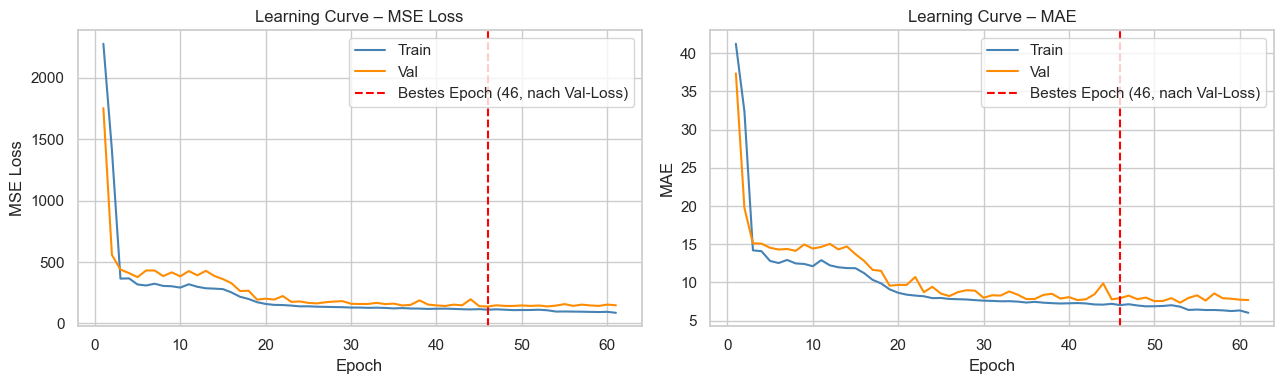

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
best_ep = int(hist.loc[hist['val_loss'].idxmin(), 'epoch'])

for ax, metric, label in zip(axes, ['loss', 'mae'], ['MSE Loss', 'MAE']):
    ax.plot(hist['epoch'], hist[metric],          label='Train', color='steelblue')
    ax.plot(hist['epoch'], hist[f'val_{metric}'], label='Val',   color='darkorange')
    ax.axvline(best_ep, color='red', linestyle='--', label=f'Bestes Epoch ({best_ep}, nach Val-Loss)')
    ax.set_title(f'Learning Curve – {label}')
    ax.set_xlabel('Epoch')
    ax.set_ylabel(label)
    ax.legend()

plt.tight_layout()
plt.savefig(REPORTS / 'lstm_learning_curves.png', dpi=150)
plt.show()
print(f'Bester Validation-Loss bei Epoch {best_ep} von {len(hist)} (Early Stopping)')

## 8. Evaluation auf dem Test-Set

In [10]:
y_pred_lstm = model.predict(X_test, verbose=0).flatten()
# Vorhersagen auf [0, RUL_CAP] clippen
y_pred_lstm = np.clip(y_pred_lstm, 0, RUL_CAP)

results_lstm = evaluate_all(y_test, y_pred_lstm, 'BiLSTM + Attention')
engine_ids   = test_raw.groupby('unit_number').size().index.values   # gleiche Reihenfolge wie X_test

if not RETRAIN:   # nur der Original-Checkpoint landet in der zentralen Ablage
    save_results(results_lstm)
    save_predictions('BiLSTM + Attention', engine_ids, y_test, y_pred_lstm)

# Vergleich mit den tabellarischen Modellen (Werte aus model_results.json, nicht abgetippt)
comparison = compare_models(list(load_results().values()) if not RETRAIN
                            else [r for k, r in load_results().items() if k != 'BiLSTM + Attention'] + [results_lstm])
print('\n=== Modellvergleich ===')
print(comparison.to_string())
rf_rmse = comparison.loc['Random Forest', 'RMSE']
print(f'\n→ BiLSTM-Verbesserung RMSE gegenüber RF: {rf_rmse - results_lstm["RMSE"]:+.2f} Zyklen')

Metriken gespeichert: model_results.json → {'Model': 'BiLSTM + Attention', 'RMSE': 13.33, 'MAE': 10.05, 'R²': 0.896, 'NASA Score': 265.4}
Vorhersagen gespeichert: predictions_test.csv (Spalte 'BiLSTM + Attention')

=== Modellvergleich ===
                     RMSE    MAE     R²  NASA Score
Model                                              
BiLSTM + Attention  13.33  10.05  0.896       265.4
XGBoost             20.45  15.21  0.756      1801.4
Random Forest       20.66  15.36  0.751      2011.9
SVR (RBF)           21.12  15.73  0.740      1809.1

→ BiLSTM-Verbesserung RMSE gegenüber RF: +7.33 Zyklen


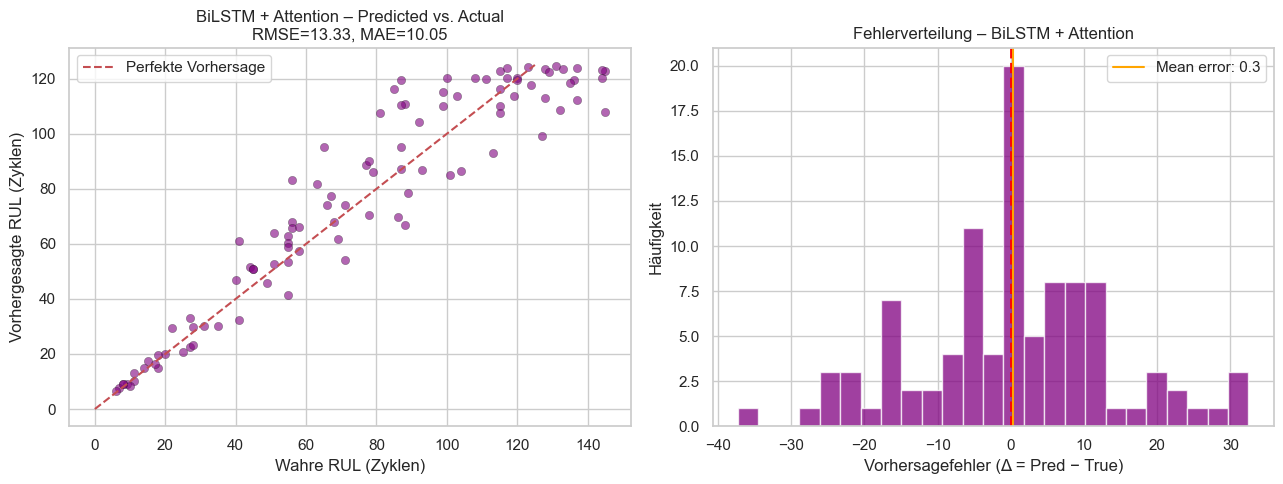

In [11]:
# Predicted vs. Actual
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Scatter
ax = axes[0]
ax.scatter(y_test, y_pred_lstm, alpha=0.6, color='purple', edgecolors='k', linewidths=0.3)
ax.plot([0, RUL_CAP], [0, RUL_CAP], 'r--', label='Perfekte Vorhersage')
ax.set_xlabel('Wahre RUL (Zyklen)')
ax.set_ylabel('Vorhergesagte RUL (Zyklen)')
ax.set_title(f'BiLSTM + Attention – Predicted vs. Actual\nRMSE={results_lstm["RMSE"]}, MAE={results_lstm["MAE"]}')
ax.legend()

# Fehler-Histogramm
ax2 = axes[1]
errors = y_pred_lstm - y_test
ax2.hist(errors, bins=25, color='purple', alpha=0.75, edgecolor='white')
ax2.axvline(0, color='red', linewidth=2, linestyle='--')
ax2.axvline(errors.mean(), color='orange', linewidth=1.5,
            label=f'Mean error: {errors.mean():.1f}')
ax2.set_xlabel('Vorhersagefehler (Δ = Pred − True)')
ax2.set_ylabel('Häufigkeit')
ax2.set_title('Fehlerverteilung – BiLSTM + Attention')
ax2.legend()

plt.tight_layout()
plt.savefig(REPORTS / 'lstm_predicted_vs_actual.png', dpi=150)
plt.show()

## 9. Attention-Gewichte

Welche Zeitschritte gewichtet das Modell? Die Gewichte kommen direkt aus der Softmax-Schicht des Attention-Poolings.  
Pro Engine summieren sie sich über die 50 Zeitschritte zu 1. Eine Gleichverteilung läge bei 1/50 = 0.02.  
Zeitschritt 0 ist der letzte beobachtete Zyklus, −49 der älteste im Fenster.

Da der Mittelwert über alle Engines Unterschiede verwischt, vergleichen wir Engines nahe am Ausfall (wahre RUL ≤ 50)  
mit gesunden Engines (RUL > 100).

RUL ≤ 50 (nahe am Ausfall)   n= 29 | Anteil letzte 10 Zyklen: Median 0.33
RUL > 100 (gesund)           n= 32 | Anteil letzte 10 Zyklen: Median 0.20
Spearman-Korrelation (Anteil letzte 10 Zyklen vs. wahre RUL): ρ = -0.78, p = 7.7e-22


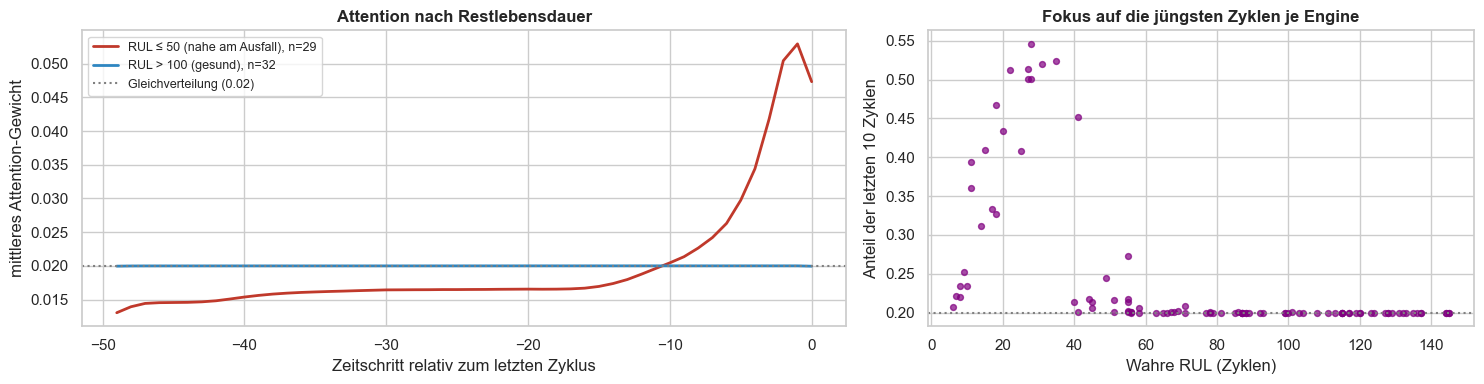

In [12]:
# Echte Attention-Gewichte: Ausgang der Softmax-Schicht im trainierten Modell
from scipy.stats import spearmanr

softmax_layer = next(l for l in model.layers if isinstance(l, layers.Softmax))
attn_model    = keras.Model(inputs=model.inputs, outputs=softmax_layer.output)
attn_weights  = attn_model.predict(X_test, verbose=0)[..., 0]          # (100 Engines, 50 Zeitschritte)
assert np.allclose(attn_weights.sum(axis=1), 1, atol=1e-4)

# Für die Website und spätere Analysen speichern
attn_df = pd.DataFrame(attn_weights, index=pd.Index(engine_ids, name='Engine'),
                       columns=[f't{t - WINDOW_SIZE + 1}' for t in range(WINDOW_SIZE)])   # t-49 … t0
if not RETRAIN:
    attn_df.to_csv(REPORTS.parent / 'lstm_attention_test.csv', float_format='%.6f')

last10 = attn_weights[:, -10:].sum(axis=1)                 # Anteil der letzten 10 Zyklen (gleichverteilt: 0.20)
groups_rul = {'RUL ≤ 50 (nahe am Ausfall)': y_test <= 50, 'RUL > 100 (gesund)': y_test > 100}

fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={'width_ratios': [1.4, 1]})
t = np.arange(-WINDOW_SIZE + 1, 1)
ax = axes[0]
for (name, mask), color in zip(groups_rul.items(), ['#c0392b', '#2e86c1']):
    ax.plot(t, attn_weights[mask].mean(axis=0), color=color, linewidth=2, label=f'{name}, n={mask.sum()}')
ax.axhline(1 / WINDOW_SIZE, color='grey', linestyle=':', label='Gleichverteilung (0.02)')
ax.set_xlabel('Zeitschritt relativ zum letzten Zyklus'); ax.set_ylabel('mittleres Attention-Gewicht')
ax.set_title('Attention nach Restlebensdauer', fontweight='bold'); ax.legend(fontsize=9)

ax = axes[1]
ax.scatter(y_test, last10, s=18, color='purple', alpha=0.7)
ax.axhline(0.2, color='grey', linestyle=':')
ax.set_xlabel('Wahre RUL (Zyklen)'); ax.set_ylabel('Anteil der letzten 10 Zyklen')
ax.set_title('Fokus auf die jüngsten Zyklen je Engine', fontweight='bold')
plt.tight_layout()
plt.savefig(REPORTS / 'lstm_attention_weights.png', dpi=150)
plt.show()

rho, p = spearmanr(last10, y_test)
for name, mask in groups_rul.items():
    print(f'{name:28s} n={mask.sum():3d} | Anteil letzte 10 Zyklen: Median {np.median(last10[mask]):.2f}')
print(f'Spearman-Korrelation (Anteil letzte 10 Zyklen vs. wahre RUL): ρ = {rho:.2f}, p = {p:.1e}')

**Interpretation:** Bei gesunden Engines ist die Attention praktisch gleichverteilt. Das Modell mittelt dann über das ganze Fenster,  
weil es dort noch keine Degradation gibt, auf die es sich konzentrieren könnte. Nahe am Ausfall verschiebt sich das Gewicht deutlich  
auf die jüngsten Zyklen, in denen sich die Sensorwerte am stärksten verändern. Am stärksten ist der Fokus bei einer RUL von etwa 15–40 Zyklen,  
ganz kurz vor dem Ausfall wird er wieder schwächer. Die Attention ist also kein fester Fokus auf das Ende des Fensters,  
sondern hängt vom Degradationszustand ab.

## 10. Vergleichsplot: BiLSTM vs. tabellarische Modelle


=== Finaler Vergleich ===
                     RMSE    MAE     R²  NASA Score
Model                                              
BiLSTM + Attention  13.33  10.05  0.896       265.4
XGBoost             20.45  15.21  0.756      1801.4
Random Forest       20.66  15.36  0.751      2011.9
SVR (RBF)           21.12  15.73  0.740      1809.1


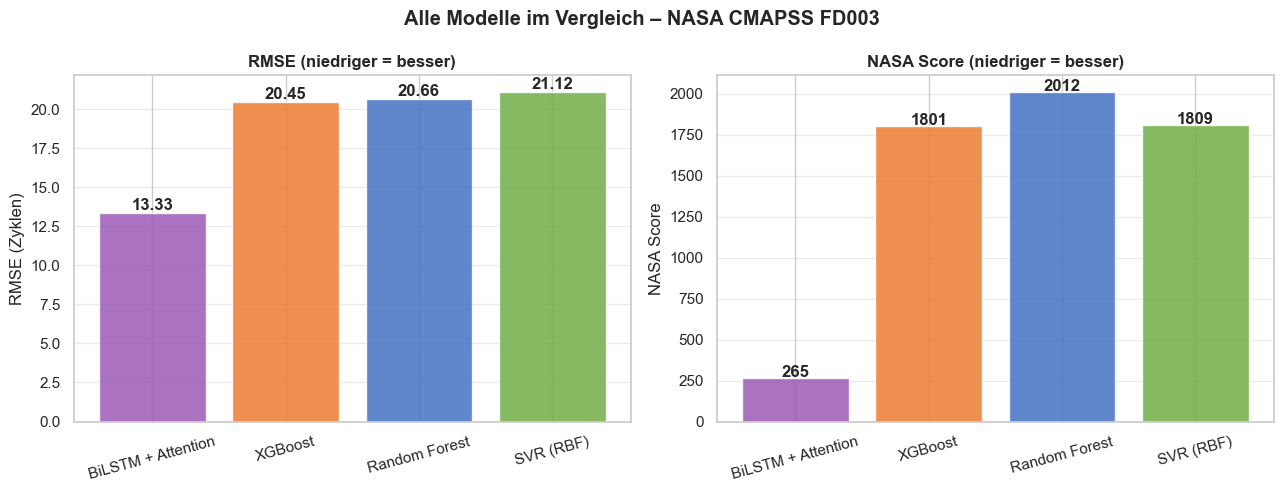

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

models_all = comparison.index.tolist()
MODEL_COLORS = {'Random Forest': '#4472C4', 'XGBoost': '#ED7D31',
                'SVR (RBF)': '#70AD47', 'BiLSTM + Attention': '#9B59B6'}
colors_all = [MODEL_COLORS.get(m, 'grey') for m in models_all]

# RMSE
ax = axes[0]
rmse_vals = comparison['RMSE'].values
bars = ax.bar(models_all, rmse_vals, color=colors_all, alpha=0.85)
for bar, val in zip(bars, rmse_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
            f'{val:.2f}', ha='center', fontweight='bold')
ax.set_title('RMSE (niedriger = besser)', fontweight='bold')
ax.set_ylabel('RMSE (Zyklen)')
ax.tick_params(axis='x', rotation=15)
ax.grid(axis='y', alpha=0.4)

# NASA Score
ax2 = axes[1]
nasa_vals = comparison['NASA Score'].values
bars2 = ax2.bar(models_all, nasa_vals, color=colors_all, alpha=0.85)
for bar, val in zip(bars2, nasa_vals):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
             f'{val:.0f}', ha='center', fontweight='bold')
ax2.set_title('NASA Score (niedriger = besser)', fontweight='bold')
ax2.set_ylabel('NASA Score')
ax2.tick_params(axis='x', rotation=15)
ax2.grid(axis='y', alpha=0.4)

plt.suptitle('Alle Modelle im Vergleich – NASA CMAPSS FD003', fontweight='bold')
plt.tight_layout()
plt.savefig(REPORTS / 'all_models_comparison.png', dpi=150)
plt.show()

print('\n=== Finaler Vergleich ===')
print(comparison.to_string())

## 11. Beispielvorhersagen: Top-10 & Worst-10

Top-10 und Worst-10 bezeichnen hier die Engines, bei denen das **beste tabellarische Modell** (RF, XGBoost oder SVR) den kleinsten  
bzw. größten Fehler hat. Die Auswahl wird aus `predictions_test.csv` berechnet, nicht von Hand eingetragen.  
Frage: Hilft der Sequenzkontext gerade dort, wo die tabellarischen Modelle versagen?

In [14]:
preds = load_predictions()
TABULAR = ['Random Forest', 'XGBoost', 'SVR (RBF)']
best_tab_err = preds[TABULAR].sub(preds['RUL_true'], axis=0).abs().min(axis=1)   # |Δ| des besten tabellarischen Modells

TOP_ENGINES   = best_tab_err.nsmallest(10).index.sort_values().tolist()
WORST_ENGINES = best_tab_err.nlargest(10).index.sort_values().tolist()
print(f'Top-10 (tabellarisch):   {TOP_ENGINES}')
print(f'Worst-10 (tabellarisch): {WORST_ENGINES}')

df_all = pd.DataFrame({
    'Wahre RUL': preds['RUL_true'].astype(int),
    'LSTM':      preds['BiLSTM + Attention'].round(1),
})
df_all['Δ']   = (df_all['LSTM'] - df_all['Wahre RUL']).round(1)
df_all['|Δ|'] = df_all['Δ'].abs()
df_all['|Δ| bestes tab. Modell'] = best_tab_err.round(1)

df_top, df_worst = df_all.loc[TOP_ENGINES], df_all.loc[WORST_ENGINES]
print('\n=== Top-10 Engines – LSTM-Vorhersage ===');   print(df_top.to_string())
print('\n=== Worst-10 Engines – LSTM-Vorhersage ==='); print(df_worst.to_string())

Top-10 (tabellarisch):   [4, 24, 25, 40, 52, 64, 78, 82, 97, 98]
Worst-10 (tabellarisch): [2, 16, 19, 54, 58, 62, 85, 89, 93, 96]

=== Top-10 Engines – LSTM-Vorhersage ===
        Wahre RUL   LSTM    Δ  |Δ|  |Δ| bestes tab. Modell
Engine                                                    
4             120  120.1  0.1  0.1                     0.5
24              9    8.9 -0.1  0.1                     0.8
25             58   57.3 -0.7  0.7                     0.5
40             41   32.3 -8.7  8.7                     0.1
52            120  119.4 -0.6  0.6                     0.5
64             28   29.8  1.8  1.8                     0.1
78             20   19.8 -0.2  0.2                     0.7
82              6    6.4  0.4  0.4                     0.7
97            123  124.1  1.1  1.1                     0.3
98             17   16.4 -0.6  0.6                     0.7

=== Worst-10 Engines – LSTM-Vorhersage ===
        Wahre RUL   LSTM     Δ   |Δ|  |Δ| bestes tab. Modell
Engine         

Top-10   – mittlerer |Fehler| LSTM:  1.43 Zyklen | bestes tabellarisches Modell je Engine: 0.1–0.8 Zyklen
Worst-10 – mittlerer |Fehler| LSTM: 18.14 Zyklen | bestes tabellarisches Modell je Engine: 31.5–58.8 Zyklen


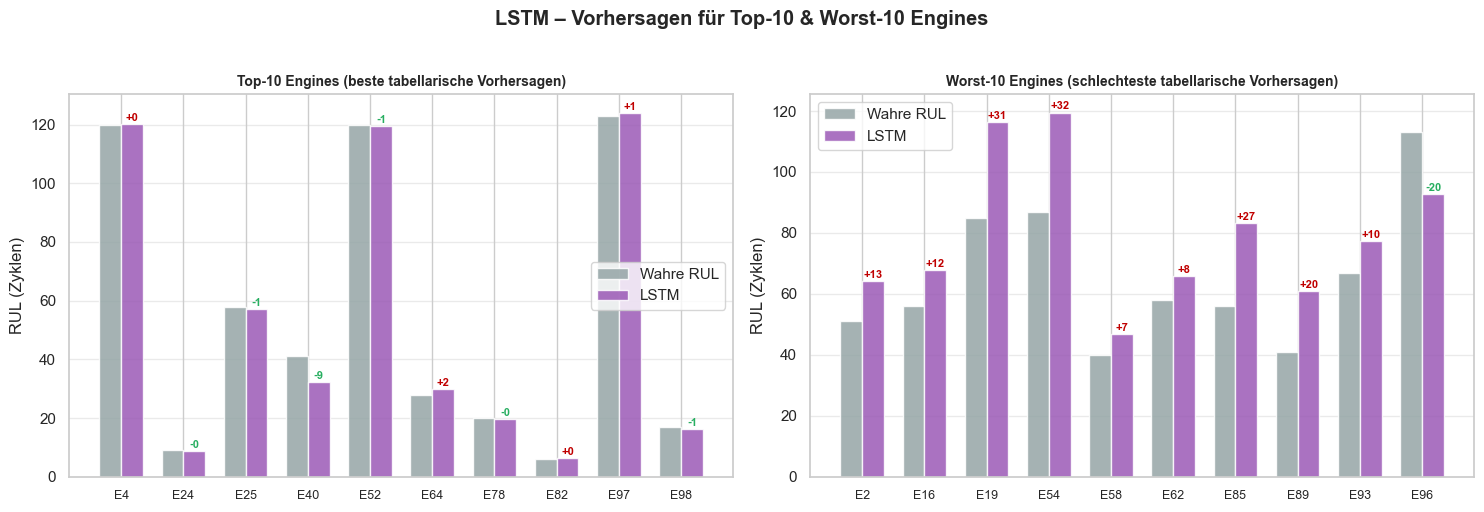

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, df, title, bar_color in zip(
    axes,
    [df_top, df_worst],
    ['Top-10 Engines (beste tabellarische Vorhersagen)',
     'Worst-10 Engines (schlechteste tabellarische Vorhersagen)'],
    ['#9B59B6', '#9B59B6']
):
    x      = np.arange(len(df))
    width  = 0.35
    labels = [f'E{eid}' for eid in df.index]

    bars = ax.bar(x - width/2, df['Wahre RUL'], width,
                  label='Wahre RUL', color='#95A5A6', alpha=0.85)
    bars2 = ax.bar(x + width/2, df['LSTM'], width,
                   label='LSTM', color=bar_color, alpha=0.85)

    # Fehler als Text über den LSTM-Balken
    for i, (bar, row) in enumerate(zip(bars2, df.itertuples())):
        color = '#c00000' if row.Δ > 0 else '#27AE60'  # Δ
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 1,
                f'{row.Δ:+.0f}',
                ha='center', fontsize=8, color=color, fontweight='bold')

    ax.set_title(title, fontweight='bold', fontsize=10)
    ax.set_ylabel('RUL (Zyklen)')
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=9)
    ax.legend()
    ax.grid(axis='y', alpha=0.4)
    ax.set_axisbelow(True)

plt.suptitle('LSTM – Vorhersagen für Top-10 & Worst-10 Engines',
             fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(REPORTS / 'lstm_top_worst_predictions.png', dpi=150, bbox_inches='tight')
plt.show()

# Zusammenfassung (berechnet, nicht abgetippt)
for name, d in [('Top-10  ', df_top), ('Worst-10', df_worst)]:
    print(f'{name} – mittlerer |Fehler| LSTM: {d["|Δ|"].mean():5.2f} Zyklen | '
          f'bestes tabellarisches Modell je Engine: {d["|Δ| bestes tab. Modell"].min():.1f}–{d["|Δ| bestes tab. Modell"].max():.1f} Zyklen')

## 12. Grenzen und nächste Schritte

**Grenzen dieses Ergebnisses:**
- Ein einzelner Validierungssplit für Early Stopping, keine 5-fach-CV
- 13.33 ist der beste von mehreren Trainingsläufen; ein Mittel über Seeds wäre konservativer
- Zero-Padding bei drei kurzen Test-Engines (siehe Abschnitt 4)
- Kontextlänge: Das BiLSTM sieht 50 Zyklen, die tabellarischen Modelle 5. Notebook 09 trennt beide Effekte.

**Mögliche Erweiterungen:**
- Mehrere Seeds und GroupKFold-CV für Mittelwert ± Standardabweichung
- Edge-Padding oder `Masking` statt Nullen
- TCN oder Transformer als alternative Sequenzmodelle
- Quantile Regression statt MSE, um Unsicherheitsintervalle pro Vorhersage zu erhalten